# T03 — Real OMIE data

*How do I replay a real trading day?*

**What you will learn**

- what OMIE publishes about its continuous intraday market, and which two daily files one contract needs;
- how to fetch only those files, and when to use the download script instead;
- how to load one real contract and replay its orders through the matching engine;
- why a replay cannot reproduce the trades that OMIE published.

**What you need**

- Previous tutorials: none. [T01](T01_first_contract.ipynb) explains the order book and price-time priority (linked, not required).
- Run time: about 2 minutes on a central processing unit (CPU), after the download.
- Network: yes, the first time. The first run downloads two monthly archives from OMIE (107.8 megabytes, MB,
  in total) and keeps four daily files (84.9 MB). Later runs, and runs without a network, skip the download.

## Setup

Imports, the device (CPU by default), the seeds, the figure style and the repository root.
Every data path is built from `ROOT`, never relative to this folder: the OMIE files go to
`<root>/data/rawOMIE`, which git ignores.

In [1]:
# Setup: device, repository root, seeds and the figure style. Run this cell first.
import os
from pathlib import Path

os.environ.setdefault("JAX_PLATFORMS", "cpu")  # CPU by default; export JAX_PLATFORMS=cuda before Jupyter for a GPU

# The repository root is the first folder above this notebook that holds pyproject.toml.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
DATA_DIR = ROOT / "data" / "rawOMIE"  # every data path starts here (ignored by git), never under tutorials/

import jax
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 0  # fixed seeds: a re-run gives the same market results
rng = np.random.default_rng(SEED)
key = jax.random.PRNGKey(SEED)

# Figure style, the same five lines in every tutorial: buy, sell, a third series, neutral.
BUY, SELL, THIRD, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9893"
plt.rcParams.update({"figure.figsize": (7, 3.2), "figure.dpi": 110, "savefig.dpi": 110, "font.size": 9.5,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "legend.frameon": False, "axes.titlesize": 10.5,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})
print(f"JAX {jax.__version__}, backend: {jax.default_backend()}")

JAX 0.6.2, backend: cpu


In [2]:
import dataclasses
import time
from datetime import date, datetime, timedelta

import jax.numpy as jnp

from omiecid_simulator.jaxomiecid.omie_data_config import OMIEDataConfig
from omiecid_simulator.jaxomiecid.omie_data_loader import load_omie_orders, replay_orders_through_book, row_to_order
from omiecid_simulator.omiecid.contract import ContractStatus, generate_contracts
from omiecid_simulator.omiecid.contract_book import ContractBook
from omiecid_simulator.omiecid.encoding import decode_price, decode_qty, encode_price, encode_qty
from omiecid_simulator.omiecid.omie_config import OMIEMarketConfig, OMIEProductConfig
from omiecid_simulator.omiecid.order_types import ExecRestriction, Side
from omiecid_simulator.omiecid.order_validator import validate_order

PC = OMIEProductConfig()  # ticks and bounds: 0.01 EUR/MWh, 0.1 MW

## 1. What OMIE publishes

> **Concept — the continuous intraday market.** OMIE (*Operador del Mercado Ibérico de Energía*) runs
> the day-ahead and intraday electricity markets of Spain and Portugal. In its continuous intraday market (CID), electricity is
> traded as 15-minute products: each *contract* is one quarter-hour of delivery. Buyers and sellers send
> orders at any time; an order that meets a matching order on the other side trades at once, and the
> others wait in the contract's *order book*. Trading on a contract opens at the gate opening time (GOT)
> and stops at its gate closure time (GCT).

OMIE publishes two files per *session day* on its website:

- the **order file** `orders_YYYYMMDD.1`: one row per order sent during that session day, with its
  contract, side (buy or sell), price in euros per megawatt-hour (EUR/MWh), quantity in megawatts
  (MW), order type and the second it was sent;
- the **trade file** `trades_YYYYMMDD.1`: one row per trade matched during that session day, with
  its price, quantity and time.

The files are published about 90 days after the session, so recent days are not available yet.

> **Concept — delivery day and session day.** A contract is named by its delivery day $D$ and its slot
> $k$, the quarter-hour of that day ($k = 0$ is 00:00–00:15, $k = 95$ is 23:45–24:00). All contracts of
> day $D$ open together at about 15:20 on day $D-1$. They close by hour: the four quarter-hours of one
> delivery hour close together, one hour before that hour starts.
> OMIE splits its files by *session day*, not by delivery day. Session day $D$ runs from 22:20 on
> $D-1$ to 22:00 on $D$. Between 22:00 and 22:20, continuous trading pauses for an intraday auction.
> A contract of day $D$ is therefore traded across two session days. The orders sent between 15:20 and
> 22:00 on $D-1$ are in the files of $D-1$. Those sent from 22:20 on $D-1$ until gate closure are in
> the files of $D$.

This tutorial uses contract $k = 81$ delivered on 12 January 2026. Its two session days, 11 and 12
January, fall in the same month, so one monthly archive per kind of file is enough.

In [3]:
DELIVERY_DAY = "2026-01-12"  # day D: the day the electricity is delivered
CONTRACT = 81                # slot k: the quarter-hour that starts at 81 x 15 minutes = 20:15

d = date.fromisoformat(DELIVERY_DAY)
midnight_d = datetime.combine(d, datetime.min.time())
start = midnight_d + timedelta(minutes=15 * CONTRACT)
got = midnight_d - timedelta(days=1) + timedelta(hours=15, minutes=20)  # gate opening: 15:20 on D-1
gct = midnight_d + timedelta(hours=CONTRACT // 4 - 1)                    # gate closure: one hour before the delivery hour
print(f"Contract {CONTRACT} of {DELIVERY_DAY}: delivery {start:%H:%M}-{start + timedelta(minutes=15):%H:%M} on {start:%a %d %b %Y}")
print(f"Gate opening:   {got:%a %d %b %H:%M}")
print(f"Gate closure:   {gct:%a %d %b %H:%M} ({(start - gct).seconds // 60} minutes before delivery starts)")
print(f"Trading window: {(gct - got).total_seconds() / 3600:.1f} hours (including two 20-minute auction pauses),"
      f" in the session files of {got:%d %b} and {gct:%d %b}")

Contract 81 of 2026-01-12: delivery 20:15-20:30 on Mon 12 Jan 2026
Gate opening:   Sun 11 Jan 15:20
Gate closure:   Mon 12 Jan 19:00 (75 minutes before delivery starts)
Trading window: 27.7 hours (including two 20-minute auction pauses), in the session files of 11 Jan and 12 Jan


## 2. Fetching the two days

OMIE publishes its files as **monthly** archives. The download script that comes with the repository
(see [Data](../docs/data.md#downloading)) fetches and extracts a whole month: for January 2026, that is
about 1.26 gigabytes (GB) of order files and 0.20 GB of trade files. To replay one contract you need four daily files:

- the order files of $D-1$ and $D$, which hold the orders;
- the trade files of $D-1$ and $D$. This tutorial does not compare with them, but the loader refuses to
  load a contract with a missing file, so that a half contract is never replayed
  ([OQ-29](../docs/omiecid/open-questions.md#oq-29--incomplete-delivery-products-a-required-session-file-missing)).

The helper below uses the same OMIE address as the download script, but keeps only those four files.
It skips the download when the four files are already in `<root>/data/rawOMIE`, and it prints a message
instead of failing when there is no network or the download breaks off. Each file is written under a
temporary name and renamed when complete, so an interrupted download never leaves a half file that looks
present. These safeguards make the helper longer than the others in these tutorials. It is the only cell
that uses the network or writes files.

Measured on 29 October 2026: the two January 2026 archives weigh 90.2 MB (orders) and 17.6 MB
(trades), 107.8 MB in total; the four files kept weigh 84.9 MB. The data is OMIE's: see the terms of
use on [OMIE's website](https://www.omie.es).

In [4]:
# A two-day download helper. OMIE publishes one archive per month and per kind of file; this helper
# downloads the month, keeps only the four daily files this tutorial needs, and deletes the archive.
import http.client
import shutil
import tempfile
import urllib.request
import zipfile

OMIE_URL = "https://www.omie.es/es/file-download?parents={kind}&filename={kind}_{month}.zip"  # the download script's address


def fetch_two_days(delivery_day, data_dir):
    """Put the orders and trades files of days D-1 and D in data_dir; return True when all four are there."""
    d = date.fromisoformat(delivery_day)
    days = [d - timedelta(days=1), d]
    assert days[0].month == d.month, "choose D so that D-1 falls in the same month (one archive per kind)"
    data_dir.mkdir(parents=True, exist_ok=True)
    wanted = [data_dir / f"{kind}_{day:%Y%m%d}.1" for kind in ("orders", "trades") for day in days]
    missing = [p for p in wanted if not p.exists()]
    if not missing:
        print(f"All four files for D = {delivery_day} are already present: no download.")
        return True
    for kind in ("orders", "trades"):
        names = {p.name for p in missing if p.name.startswith(kind)}
        if not names:
            continue
        url = OMIE_URL.format(kind=kind, month=f"{d:%Y%m}")
        try:
            with tempfile.TemporaryDirectory(dir=data_dir) as tmp:  # under data_dir (ignored by git), deleted afterwards
                archive = Path(tmp) / "month.zip"
                with urllib.request.urlopen(url, timeout=60) as r, open(archive, "wb") as f:
                    shutil.copyfileobj(r, f)
                print(f"Downloaded the {kind} archive for {d:%B %Y}: {archive.stat().st_size / 1e6:.1f} MB")
                with zipfile.ZipFile(archive) as z:
                    for entry in z.namelist():
                        name = Path(entry).name  # the file name only: nothing is written outside data_dir
                        if name in names:
                            part = data_dir / (name + ".part")
                            with z.open(entry) as src, open(part, "wb") as dst:
                                shutil.copyfileobj(src, dst)
                            part.rename(data_dir / name)  # the file appears only once it is complete
                            print(f"  kept {name}: {(data_dir / name).stat().st_size / 1e6:.1f} MB")
        except (OSError, zipfile.BadZipFile, http.client.HTTPException) as exc:  # no network, a firewall, the site down, or a cut-off download
            print(f"Could not download or open the {kind} archive ({type(exc).__name__}). "
                  "The cells that need real data will be skipped.")
            return False
    still_missing = [p.name for p in wanted if not p.exists()]
    if still_missing:
        print(f"The OMIE archives do not hold {', '.join(still_missing)}. The cells that need real data will be skipped.")
    return not still_missing


HAVE_DATA = fetch_two_days(DELIVERY_DAY, DATA_DIR)
SKIPPED = "Skipped: the OMIE files are not available (see the download cell above)."

All four files for D = 2026-01-12 are already present: no download.


**Downloading many days.** For bulk work, use the download script from the repository root. It
fetches whole months and extracts every daily file into `data/rawOMIE`:

```bash
python -m scripts.download_omie_data --months 202601 --data-type orders
python -m scripts.download_omie_data --months 202601 --data-type trades
python -m scripts.download_omie_data --months 202601 --dry-run   # print what it would do, no network
```

Three things to know. It extracts the whole month even when you pass `--date`. It skips a month as soon
as *any* file of that month is present, so a month cut short by an interrupted run stays incomplete:
delete that month's files and run it again. And it keeps each archive in the hidden folder
`data/rawOMIE/.zips`, which you can delete after the extraction.

## 3. Loading one contract

`OMIEDataConfig` names the folder, the delivery day and the slot. `load_omie_orders` reads the two
order files, keeps the rows of that one contract, sorts them by the second they were sent, and returns
a *tape*: one row of 13 whole numbers per order, in time order.

> **Concept — integer ticks.** The engine stores every price and quantity as a whole number of *ticks*:
> 0.01 EUR/MWh for prices and 0.1 MW for quantities. A price $p$ is stored as
> $(p - p_{\min}) / 0.01$ with $p_{\min} = -9{,}999$ EUR/MWh, so it is never negative. Whole numbers are
> exact, where decimal numbers in binary floating point are not. The tables below decode the ticks back
> to EUR/MWh and MW.

Times in the tape count the seconds since 00:00 on day $D-1$.

In [5]:
TYPES = {0: "limit (NON)", 1: "immediate-or-cancel (IOC)", 2: "fill-or-kill (FOK)", 3: "iceberg (ICE)"}


def as_table(rows):
    # Decode tape rows for reading: clock times, sides, order types, EUR/MWh and MW.
    day_before = midnight_d - timedelta(days=1)
    return pd.DataFrame({
        "order": rows[:, 4],
        "sent at": [f"{day_before + timedelta(seconds=int(s)):%d %b %H:%M:%S}" for s in rows[:, 6]],
        "side": np.where(rows[:, 1] == Side.BUY, "buy", "sell"),
        "type": [TYPES[int(x)] for x in rows[:, 7]],
        "price (EUR/MWh)": [f"{decode_price(int(p), PC):.2f}" for p in rows[:, 2]],
        "quantity (MW)": [f"{decode_qty(int(q), PC):.1f}" for q in rows[:, 3]],
        "visible peak (MW)": [f"{decode_qty(int(q), PC):.1f}" if q else "" for q in rows[:, 11]],
    }).set_index("order")


if HAVE_DATA:
    config = OMIEDataConfig(data_path=str(DATA_DIR), contract_id=CONTRACT, delivery_date=DELIVERY_DAY)
    orders = np.asarray(load_omie_orders(config))  # (N, 13) int32, sorted by send time
    print(f"{len(orders)} orders: {(orders[:, 1] == Side.BUY).sum()} buys and {(orders[:, 1] == Side.SELL).sum()} sells")
    for code, name in TYPES.items():
        print(f"  {name:27s} {(orders[:, 7] == code).sum():5d}")
    print()
    print(as_table(orders[:6]).to_string())
else:
    print(SKIPPED)

2864 orders: 1398 buys and 1466 sells
  limit (NON)                  2020
  immediate-or-cancel (IOC)      71
  fill-or-kill (FOK)             10
  iceberg (ICE)                 763

               sent at  side           type price (EUR/MWh) quantity (MW) visible peak (MW)
order                                                                                      
1      11 Jan 15:20:16   buy  iceberg (ICE)            6.85          50.0              10.0
2      11 Jan 15:20:40   buy  iceberg (ICE)            6.85          50.0              10.0
3      11 Jan 15:20:52  sell  iceberg (ICE)         2000.00          30.0               5.0
4      11 Jan 15:21:30   buy  iceberg (ICE)           86.85          50.0              10.0
5      11 Jan 15:21:49  sell    limit (NON)          138.29           2.9                  
6      11 Jan 15:21:54   buy  iceberg (ICE)           86.85          50.0              10.0


The iceberg rows show their *visible peak*: an iceberg order shows only part of its quantity at a time
(see [T02](T02_order_types.ipynb)).

**One order, checked by the validator.** The engine accepts an order only if it passes the checks it
models: price and quantity within their bounds, the contract open, and, for an iceberg, a peak no larger
than its total quantity. A price or quantity between two ticks is rounded to the nearest tick, not
rejected. The checks of the participant's guarantee and of the system operator's limits are not modelled
([Market model › Validation](../docs/market-model.md#validation)). A sell of 2.5 MW
at 129.68 EUR/MWh is a good test, because 129.68 has no exact binary floating-point form. The loader
stores its price as a whole number of ticks, and the validator accepts it.

In [6]:
if HAVE_DATA:
    price_tick, qty_tick = encode_price(129.68, PC), encode_qty(2.5, PC)
    print(f"129.68 EUR/MWh is stored as tick {price_tick:,}, and 2.5 MW as tick {qty_tick}")
    same = (orders[:, 1] == Side.SELL) & (orders[:, 7] == ExecRestriction.NON) \
        & (orders[:, 2] == price_tick) & (orders[:, 3] == qty_tick)
    for row in orders[same]:
        order = row_to_order(row, PC)
        accepted = bool(validate_order(order, PC, contract_open=True))
        print(f"order {order.order_id}: sell {order.quantity:.1f} MW at {order.price:.2f} EUR/MWh"
              f" -> {'accepted' if accepted else 'rejected'}")
else:
    print(SKIPPED)

129.68 EUR/MWh is stored as tick 1,012,868, and 2.5 MW as tick 25
order 1653: sell 2.5 MW at 129.68 EUR/MWh -> accepted
order 1659: sell 2.5 MW at 129.68 EUR/MWh -> accepted


## 4. Replaying the contract

A replay sends the tape's orders, one by one and in time order, to an empty order book of the
contract. Each order either trades with the orders already waiting, or waits in the book itself.

> **Concept — the replay rule.** The order file is a log of submissions only: it does not say when an
> order was cancelled. The replay therefore keeps every limit or iceberg order that does not trade in the
> book until gate closure. (Immediate-or-cancel and fill-or-kill orders never wait. An immediate-or-cancel
> order trades what it can at once and the rest is cancelled. A fill-or-kill order trades in full at once,
> or not at all.) Section 6 explains what this means for the result.

Three settings matter:

- **An open contract.** `generate_contracts()` creates the 96 contracts of a day, all *pending*. The
  package has no public helper to open one, so the cell sets the status with one line.
- **Room in the book.** Since the replay never cancels a waiting order, orders pile up. By default the
  book holds 100 waiting orders per side, and drops the worst-priced ones when a side is full.
  `book_depth=2048` keeps them all; `book_full` tells whether the limit was ever reached. Icebergs also
  need a slot each (`max_icebergs`, 1,024 by default); `truncated` tells whether they ran out.
- **Room for the trades.** The book records up to `nTrades` trades (100 by default); `4096` leaves a
  wide margin. Once the buffer is full, each new order records only one of its trades, and the others
  are lost without warning. A count below `nTrades` therefore proves that nothing was lost.

`replay_orders_through_book` can also count how many of OMIE's published trades the replay reproduces.
This tutorial does not compare (section 6 explains why an exact match is impossible), so it passes an
empty array instead of the published trades.

In [7]:
if HAVE_DATA:
    contract = dataclasses.replace(generate_contracts()[CONTRACT], status=ContractStatus.OPEN)
    capacity = OMIEMarketConfig(book_depth=2048, nTrades=4096)
    book = ContractBook(contract, market_config=capacity)
    no_comparison = jnp.zeros((0, 6), dtype=jnp.int32)

    t0 = time.perf_counter()
    result = replay_orders_through_book(jnp.asarray(orders), book, no_comparison)
    print(f"Replayed {len(orders)} orders in {time.perf_counter() - t0:.0f} s (this includes compiling the engine)")
    trades = np.asarray(result.replayed_trades)  # one row per trade: price (EUR/MWh), quantity (MW), aggressor order
    print(f"A side of the book was full at some point: {'yes' if bool(result.final_state.book_full) else 'no'}")
    print(f"Iceberg slots overflowed: {'yes' if bool(result.final_state.truncated) else 'no'} (room for {capacity.max_icebergs} icebergs)")
    print(f"Trade buffer: {len(trades)} trades recorded, below its {capacity.nTrades} rows, so none was lost")
else:
    print(SKIPPED)

Replayed 2864 orders in 44 s (this includes compiling the engine)
A side of the book was full at some point: no
Iceberg slots overflowed: no (room for 1024 icebergs)
Trade buffer: 555 trades recorded, below its 4096 rows, so none was lost


## 5. The simulated trades

Each trade has a price, a quantity and the order that triggered it: the *aggressor*, the newly arrived
order that met an order already waiting. The trade time is the aggressor's send time. The summary uses
the volume-weighted average price, in which each trade counts in proportion to its quantity:

$$\bar p = \frac{\sum_i p_i \, q_i}{\sum_i q_i}.$$

Quantities are power, in MW, over a 15-minute delivery period, so a trade of $q$ MW delivers
$q \cdot 0.25$ MWh of energy.

In [8]:
if HAVE_DATA:
    price = np.round(trades[:, 0].astype(float), 2)
    qty = np.round(trades[:, 1].astype(float), 1)
    aggressor = trades[:, 2].astype(int)
    assert (orders[aggressor - 1, 4] == aggressor).all()  # order ids are 1..N in tape order
    delivery_start_s = 86_400 + 900 * CONTRACT             # delivery start, in seconds since 00:00 on D-1
    hours_before = (orders[aggressor - 1, 6] - delivery_start_s) / 3600  # negative: -2.0 is two hours before delivery

    vwap = (price * qty).sum() / qty.sum()
    print(f"Simulated trades:              {len(trades)}")
    print(f"Traded quantity:               {qty.sum():.1f} MW ({qty.sum() * 0.25:.1f} MWh of energy)")
    print(f"Volume-weighted average price: {vwap:.2f} EUR/MWh")
    print(f"Lowest and highest price:      {price.min():.2f} and {price.max():.2f} EUR/MWh")
    print(f"First and last trade:          {-hours_before.min():.1f} and {-hours_before.max():.1f} hours before delivery")
else:
    print(SKIPPED)

Simulated trades:              555
Traded quantity:               997.9 MW (249.5 MWh of energy)
Volume-weighted average price: 112.94 EUR/MWh
Lowest and highest price:      104.71 and 118.08 EUR/MWh
First and last trade:          28.9 and 1.3 hours before delivery


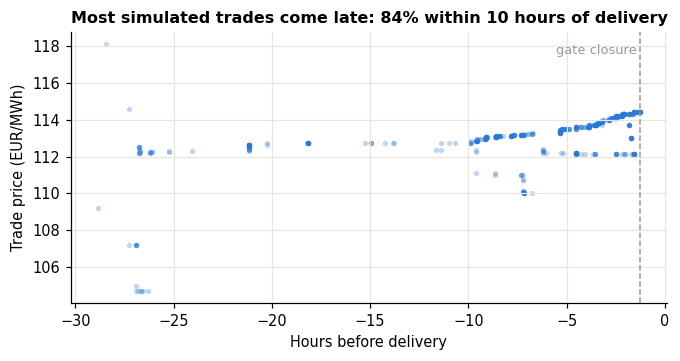

In [9]:
# One question, one figure: when, and at what price, did the replay trade?
if HAVE_DATA:
    gct_hours = -(start - gct).seconds / 3600
    fig, ax = plt.subplots()
    ax.scatter(hours_before, price, s=12, color=BUY, alpha=0.3, lw=0)
    ax.axvline(gct_hours, color=GREY, ls="--", lw=1)
    ax.text(gct_hours - 0.2, price.max(), "gate closure", ha="right", va="top", color=GREY, fontsize=8.5)
    ax.set_xlabel("Hours before delivery")
    ax.set_ylabel("Trade price (EUR/MWh)")
    late = (hours_before > -10).mean()  # share of the trades in the last 10 hours before delivery
    ax.set_title(f"Most simulated trades come late: {late:.0%} within 10 hours of delivery")
    plt.show()
else:
    print(SKIPPED)

## 6. Why a replay cannot reproduce the published trades

The replay above is a faithful run of the matching engine on the public order log. It is not a copy of
what happened in the market. The difference has two sources. The first is what the public record
leaves out. The second is the replay's own simplifications: for example, it carries the book across
the intraday-auction pauses without the batch re-match that reopens continuous trading
([Modelling assumptions › Simplifications](../docs/modelling-assumptions.md#simplifications)). In short:

> Compatibility with public data is a key differentiator: OMIE's published CID order and trade files load out of the box, and real sessions can be replayed. Exact reproduction of the published trades is nevertheless impossible, because the public record has three gaps:
>
> - **Order lifecycles.** The order file is a log of submissions only. It carries no order identifiers or status, and no modification, cancellation, or expiry events.
> - **Cross-border counterparties.** In cross-border trades the non-Iberian counterparty is left blank, and its order never appears in the order file.
> - **Incompletely disclosed order attributes.** The validity field carries no expiry time, and timestamps have one-second resolution, so the time priority of simultaneous orders is unknown.

Where each gap is discussed:

- **Order lifecycles:** [OQ-10, cancelled orders are not identifiable in the public data](../docs/omiecid/open-questions.md#oq-10--cancelled-orders-not-identifiable-in-omie-public-data);
  [Modelling assumptions › Replaying public OMIE data](../docs/modelling-assumptions.md#replaying-public-omie-data);
  [market specification §13.4](../docs/omiecid/market-spec.md#134-notes-for-data-loading-m7) (no order identifier, no status).
- **Cross-border counterparties:** [Modelling assumptions › Simplifications](../docs/modelling-assumptions.md#simplifications) (single local book, no cross-border flow);
  [market specification §3.1](../docs/omiecid/market-spec.md#31-continuous-market-gate-times), scope note (the public files hold Iberian participants' orders, and a cross-border trade shows one side blank);
  [§13.2](../docs/omiecid/market-spec.md#132-trades-file-columns) (the buyer and seller columns of the trade file).
- **Incompletely disclosed order attributes:** [market specification §13.1](../docs/omiecid/market-spec.md#131-orders-file-columns) (validity and send-time columns);
  [OQ-32, same-second arrival order](../docs/omiecid/open-questions.md#oq-32--same-second-arrival-order-in-replay).

Two of the gaps act directly on the replay's book. An order that was cancelled in the market stays in
the replay's book until gate closure, so later orders can trade with liquidity that had in fact been
withdrawn. That is why the book above needed room for so many waiting orders. And the orders of
non-Iberian counterparties are missing. An Iberian order that was really filled from abroad also
stays in the replay's book. An Iberian order that really traded with a foreign order may find nothing
to trade with here. This tutorial does not measure which effect is larger.

## Recap

- OMIE publishes an order file and a trade file per session day; a contract delivered on day $D$ needs
  the files of $D-1$ and $D$, and the loader needs both kinds.
- A small helper can fetch just those four files; the download script is for whole months.
- `load_omie_orders` turns one contract into a tape of integer ticks; `replay_orders_through_book` runs
  it through the engine, keeping every untraded limit or iceberg order until gate closure.
- Give the book room (`book_depth`, `nTrades`) and check `book_full`, `truncated` and the trade count.
- The public record has three gaps and the replay simplifies the market, so a replay is a model of the
  day, not a copy of its trades.

## Exercises

1. **When does the trading happen?** Count the simulated trades in each whole hour before delivery, and
   find the busiest hour. *Hint:* `np.floor(hours_before)` and `np.unique(..., return_counts=True)`.
2. **A full book.** Replay the same tape with the default room of 100 waiting orders per side (keep
   `nTrades=4096`). Does `book_full` turn true? How many trades does the replay make now? *Hint:*
   `OMIEMarketConfig(nTrades=4096)`.
3. **A neighbour contract.** Load contract 80 (20:00–20:15) of the same day and count its orders by type.
   Why does it need no new download? *Hint:* which session files does it span?

The solutions are in the collapsed cell at the end.

## Further reading

- [Data](../docs/data.md): the tape layout, the download script, the loader and a real-data session.
- [Modelling assumptions](../docs/modelling-assumptions.md#replaying-public-omie-data) and the
  [market model](../docs/market-model.md).
- The evidence: [the market specification §13](../docs/omiecid/market-spec.md#131-orders-file-columns) (OMIE's
  file formats) and [the open questions](../docs/omiecid/open-questions.md).
- Other tutorials: [T04](T04_synthetic_flow.ipynb) builds order flow without real data;
  [T05](T05_session.ipynb) trades in a running session; [T08](T08_overseers_view.ipynb) looks inside the
  book as the market operator does.

## Solutions

In [10]:
# Solutions to the exercises (collapsed; expand to read).
if HAVE_DATA:
    # 1. Trades per whole hour before delivery.
    hour, count = np.unique(np.floor(hours_before).astype(int), return_counts=True)
    busiest = hour[count.argmax()]
    print(f"1. Busiest hour: from {-busiest} to {-busiest - 1} hours before delivery, with {count.max()} trades")

    # 2. The default room of 100 waiting orders per side.
    small = ContractBook(contract, market_config=OMIEMarketConfig(nTrades=4096))
    small_result = replay_orders_through_book(jnp.asarray(orders), small, no_comparison)
    print(f"2. book_full: {bool(small_result.final_state.book_full)}; trades: {len(small_result.replayed_trades)}"
          f" (with room for every order: {len(trades)})")

    # 3. Contract 80 is delivered on the same day, so it spans the same two session files.
    other = np.asarray(load_omie_orders(dataclasses.replace(config, contract_id=80)))
    print(f"3. Contract 80: {len(other)} orders; " + ", ".join(f"{name} {(other[:, 7] == c).sum()}" for c, name in TYPES.items()))
else:
    print(SKIPPED)

1. Busiest hour: from 3 to 2 hours before delivery, with 91 trades


2. book_full: True; trades: 556 (with room for every order: 555)


3. Contract 80: 2503 orders; limit (NON) 1971, immediate-or-cancel (IOC) 51, fill-or-kill (FOK) 12, iceberg (ICE) 469
